### Portions of this code have been modified from: https://www.tensorflow.org/tutorials/generative/style_transfer

# Setup

In [2]:
%pip install -q scikit-image ipywidgets

### Imports

In [3]:
import tensorflow as tf
from pathlib import Path
from datetime import datetime
import shutil
import ipywidgets as widgets
from IPython.display import display
import matplotlib.pyplot as plt
import matplotlib as mpl
mpl.rcParams['figure.figsize'] = (12, 12)
mpl.rcParams['axes.grid'] = False
import numpy as np
from PIL import Image, ImageOps
import time

## Mount drive

In [4]:
# mount google drive to save checkpoints and output images
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Image Preparation
Image processing functions: load and display content and style images, preserve content image colors if desired

In [5]:
def tensor_to_image(tensor):
  """convert a tensor to an image with NumPy and Pillow"""
  tensor = tensor*255
  tensor = np.array(tensor, dtype=np.uint8)
  if np.ndim(tensor)>3:
    assert tensor.shape[0] == 1
    tensor = tensor[0]
  return Image.fromarray(tensor)

def imshow(image, title=None):
  """visualize an image with Matplotlib"""
  if len(image.shape) > 3:
    image = tf.squeeze(image, axis=0)

  plt.imshow(image)
  if title:
    plt.title(title)

def load_img(path_to_img):
  """load an image and limit its max dims to 512 pixels"""
  max_dim = 512

  with Image.open(path_to_img) as pil_img:
      pil_img = ImageOps.exif_transpose(pil_img)
      pil_img = pil_img.convert("RGB")
      img = tf.convert_to_tensor(np.array(pil_img))

  img = tf.image.convert_image_dtype(img, tf.float32)

  shape = tf.cast(tf.shape(img)[:-1], tf.float32)
  long_dim = max(shape)
  scale = max_dim / long_dim

  new_shape = tf.cast(shape * scale, tf.int32)

  img = tf.image.resize(img, new_shape)
  img = img[tf.newaxis, :]
  return img

def preserve_content_colors(stylized_image, content_image):
    """Transfer the content image's colors to the stylized result."""

    def to_array(image):
        if hasattr(image, "numpy"):
            image = image.numpy()
        image = np.squeeze(image)
        return np.clip(image, 0, 1)

    stylized = to_array(stylized_image)
    content = to_array(content_image)

    # Convert images to LAB color space
    from skimage.color import rgb2lab, lab2rgb

    stylized_lab = rgb2lab(stylized)
    content_lab = rgb2lab(content)

    # Keep stylized luminance and original content colors
    stylized_lab[:, :, 1:] = content_lab[:, :, 1:]

    result = lab2rgb(stylized_lab)

    return Image.fromarray(
        (np.clip(result, 0, 1) * 255).astype(np.uint8)
    )

# User inputs
- content photo
- style photo
- color selection dropdown (style photo or content photo color scheme)
- workflow selector allows you to try out both color options on an image without retraining:
  - generate new image by retraining with user's uploaded images
  - load a previously trained image from the most recently saved checkpoint in google drive without repeating the training process

## Widgets for uploading user's content and style images

In [6]:
# set up the widgets
content_upload = widgets.FileUpload(
    accept="image/*",
    multiple=False,
    description="Content Image"
)

style_upload = widgets.FileUpload(
    accept="image/*",
    multiple=False,
    description="Style Image"
)

display(widgets.VBox([
    widgets.HTML("<b>Choose your content and style images:</b>"),
    content_upload,
    style_upload
]))

def save_uploaded_image(widget, prefix):
    """widget function to save images"""
    if not widget.value:
        raise ValueError(f"Please upload a {prefix} image.")

    files = widget.value

    # Handle ipywidgets 7 and 8
    if isinstance(files, dict):
        filename, file_info = next(iter(files.items()))
    else:
        file_info = files[0]
        filename = file_info.get("name") or file_info.get("metadata", {}).get("name")

    if not filename:
        raise ValueError("Could not determine the uploaded filename.")

    destination = Path(f"{prefix}_{Path(filename).name}")
    destination.write_bytes(bytes(file_info["content"]))

    return str(destination)

def prepare_images():
    global content_path, style_path

    content_path = save_uploaded_image(content_upload, "content")
    style_path = save_uploaded_image(style_upload, "style")

    print("Content image:", content_path)
    print("Style image:", style_path)

prepare_button = widgets.Button(
    description="Use Uploaded Images",
    button_style="success"
)

def on_prepare_clicked(button):
    try:
        prepare_images()
    except Exception as error:
        print("Error:", error)

prepare_button.on_click(on_prepare_clicked)
display(prepare_button)


Button(button_style='success', description='Use Uploaded Images', style=ButtonStyle())

Content image: content_winterserious.jpg
Style image: style_notredame (1).jpg


## Widgets for color mode, and train new image or restore previously trained result

In [7]:
# maintain the colors from the content image or use the colors from the style image
color_mode = widgets.Dropdown(
    options=[
        ("Use style image colors", "style"),
        ("Preserve original content colors", "content")
    ],
    value="style",
    description="Colors:",
    style={"description_width": "initial"}
)

display(color_mode)

Dropdown(description='Colors:', options=(('Use style image colors', 'style'), ('Preserve original content colo…

In [8]:
# generate a new stylized image using uploaded photos or
# load a previously trained result without repeating optimization
workflow = widgets.Dropdown(
    options=[
        ("Train a new image", "train"),
        ("Restore a saved image", "restore")
    ],
    value="train",
    description="Workflow:",
    style={"description_width": "initial"}
)

display(workflow)

Dropdown(description='Workflow:', options=(('Train a new image', 'train'), ('Restore a saved image', 'restore'…

In [9]:
# Select a previously trained image checkpoint
checkpoint_dir = Path("/content/drive/MyDrive/StyleTransfer_Checkpoints")

def get_saved_checkpoints():
    checkpoints = sorted(
        checkpoint_dir.glob("*.npy"),
        key=lambda p: p.stat().st_mtime,
        reverse=True
    )
    return [(p.name, str(p)) for p in checkpoints]

checkpoint_selector = widgets.Dropdown(
    options=get_saved_checkpoints(),
    description="Saved image:",
    style={"description_width": "initial"}
)

display(checkpoint_selector)

Dropdown(description='Saved image:', options=(('trained_image_20261104_191245.npy', '/content/drive/MyDrive/St…

## View original images before any training/style transfer

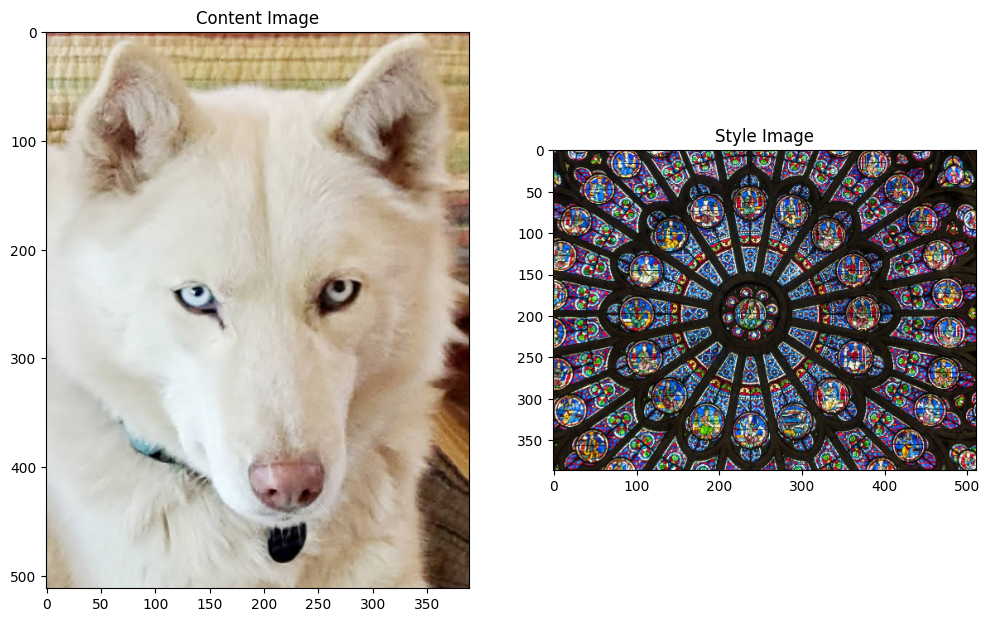

In [11]:
# view both images before any modifications
content_image = load_img(content_path)
style_image = load_img(style_path)

plt.subplot(1, 2, 1)
imshow(content_image, 'Content Image')

plt.subplot(1, 2, 2)
imshow(style_image, 'Style Image')

# VGG19 Model:
Content and style representations with VGG19:  

VGG19 is a 19 layer neural network that has been pretrained on the ImageNet database for the purposes of image classifications.
According to the above referenced tutorial, the intermediate layers of the VGG19 network will essentially extract features of both the style and the content images so that one image's style can be applied to the other image's content without making any changes to the content.

## Load a pre-trained VGG19 model and test run its classification on our image
reference site: https://keras.io/api/applications/vgg/#vgg19-function


In [12]:
# preprocess image for VGG19 architecture
x = tf.keras.applications.vgg19.preprocess_input(content_image*255)
x = tf.image.resize(x, (224, 224))

# load the VGG19 model the imagenet weights and the classification head
vgg = tf.keras.applications.VGG19(include_top=True, weights='imagenet') # include_top means include the classification head
prediction_probabilities = vgg(x)
prediction_probabilities.shape

574710816/574710816 ━━━━━━━━━━━━━━━━━━━━ 29s 0us/step


TensorShape([1, 1000])

In [13]:
# top five classification predictions for fun
predicted_top_5 = tf.keras.applications.vgg19.decode_predictions(prediction_probabilities.numpy())[0]
[(class_name, prob) for (number, class_name, prob) in predicted_top_5]

35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


[('Eskimo_dog', np.float32(0.5184433)),
 ('Siberian_husky', np.float32(0.2861325)),
 ('white_wolf', np.float32(0.10897497)),
 ('dingo', np.float32(0.023550482)),
 ('Samoyed', np.float32(0.020091938))]

# Model Setup

## Load a VGG19 model without the classification head and define style/content layers, Gram matrix, and feature extractor

In [14]:
# load model and list layer names
vgg = tf.keras.applications.VGG19(include_top=False, weights='imagenet')
print()
for layer in vgg.layers:
  print(layer.name)

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step

input_layer_1
block1_conv1
block1_conv2
block1_pool
block2_conv1
block2_conv2
block2_pool
block3_conv1
block3_conv2
block3_conv3
block3_conv4
block3_pool
block4_conv1
block4_conv2
block4_conv3
block4_conv4
block4_pool
block5_conv1
block5_conv2
block5_conv3
block5_conv4
block5_pool


In [15]:
# Select intermediate layers from the architecture to represent the
# style and content of the image

content_layers = ['block5_conv2']

style_layers = ['block1_conv1',
                'block2_conv1',
                'block3_conv1',
                'block4_conv1',
                'block5_conv1']

num_content_layers = len(content_layers)
num_style_layers = len(style_layers)

# print the number of style and content layers
print(num_content_layers)
print(num_style_layers)

1
5


In [16]:
def vgg_layers(layer_names):
  """Builds a VGG19 model that returns a list of intermediate layer outputs
"""
  # load pretrained VGG (trained on ImageNet data)
  vgg = tf.keras.applications.VGG19(include_top=False, weights='imagenet')
  vgg.trainable = False

  outputs = [vgg.get_layer(name).output for name in layer_names]

  model = tf.keras.Model([vgg.input], outputs)
  return model

In [17]:
# create the model:
style_extractor = vgg_layers(style_layers) # the model
style_outputs = style_extractor(style_image*255)

#Look at the statistics of each layer's output
for name, output in zip(style_layers, style_outputs):
  print(name)
  print("  shape: ", output.numpy().shape)
  print("  min: ", output.numpy().min())
  print("  max: ", output.numpy().max())
  print("  mean: ", output.numpy().mean())
  print()

block1_conv1
  shape:  (1, 387, 511, 64)
  min:  0.0
  max:  838.0661
  mean:  32.220734

block2_conv1
  shape:  (1, 193, 255, 128)
  min:  0.0
  max:  5227.571
  mean:  227.91763

block3_conv1
  shape:  (1, 96, 127, 256)
  min:  0.0
  max:  11870.334
  mean:  281.0771

block4_conv1
  shape:  (1, 48, 63, 512)
  min:  0.0
  max:  23581.008
  mean:  975.5207

block5_conv1
  shape:  (1, 24, 31, 512)
  min:  0.0
  max:  3717.6086
  mean:  83.572266



## Gram matrix: the style of an image


In [18]:
def gram_matrix(input_tensor):
  """
  "The content of an image is represented by the values of the intermediate
  feature maps. The style can be described by the means ans correlations across
  the different feature maps. Calculate a Gram Matrix. This can be implemented
  concisely using the `tf.linalg.einsum` function."
  reference: https://www.tensorflow.org/tutorials/generative/style_transfer
  """

  result = tf.linalg.einsum('bijc,bijd->bcd', input_tensor, input_tensor)
  input_shape = tf.shape(input_tensor)
  num_locations = tf.cast(input_shape[1]*input_shape[2], tf.float32)
  return result/(num_locations)

## Style Content Model Class

In [19]:
# Build a model that returns the style and content tensors.
class StyleContentModel(tf.keras.models.Model):
  def __init__(self, style_layers, content_layers):
    super(StyleContentModel, self).__init__()
    self.vgg = vgg_layers(style_layers + content_layers)
    self.style_layers = style_layers
    self.content_layers = content_layers
    self.num_style_layers = len(style_layers)
    self.vgg.trainable = False

  def call(self, inputs):
    # Expects float input in [0,1]
    inputs = inputs*255.0
    preprocessed_input = tf.keras.applications.vgg19.preprocess_input(inputs)
    outputs = self.vgg(preprocessed_input)
    style_outputs, content_outputs = (outputs[:self.num_style_layers],
                                      outputs[self.num_style_layers:])

    style_outputs = [gram_matrix(style_output)
                     for style_output in style_outputs]

    content_dict = {content_name: value
                    for content_name, value
                    in zip(self.content_layers, content_outputs)}

    style_dict = {style_name: value
                  for style_name, value
                  in zip(self.style_layers, style_outputs)}

    return {'content': content_dict, 'style': style_dict}

## Feature Extraction

In [20]:
# When called on an image, this model returns the gram matrix (style) of the `style_layers`
# and content of the `content_layers`:
extractor = StyleContentModel(style_layers, content_layers) # the model

results = extractor(tf.constant(content_image))

print('Styles:')
for name, output in sorted(results['style'].items()):
  print("  ", name)
  print("    shape: ", output.numpy().shape)
  print("    min: ", output.numpy().min())
  print("    max: ", output.numpy().max())
  print("    mean: ", output.numpy().mean())
  print()

print("Contents:")
for name, output in sorted(results['content'].items()):
  print("  ", name)
  print("    shape: ", output.numpy().shape)
  print("    min: ", output.numpy().min())
  print("    max: ", output.numpy().max())
  print("    mean: ", output.numpy().mean())


Styles:
   block1_conv1
    shape:  (1, 64, 64)
    min:  0.010930914
    max:  67680.59
    mean:  231.98718

   block2_conv1
    shape:  (1, 128, 128)
    min:  0.0
    max:  76267.766
    mean:  7274.985

   block3_conv1
    shape:  (1, 256, 256)
    min:  0.0
    max:  211855.86
    mean:  6135.514

   block4_conv1
    shape:  (1, 512, 512)
    min:  0.0
    max:  1.7061315e+06
    mean:  112942.53

   block5_conv1
    shape:  (1, 512, 512)
    min:  0.0
    max:  64670.76
    mean:  1090.3896

Contents:
   block5_conv2
    shape:  (1, 32, 24, 512)
    min:  0.0
    max:  1266.5784
    mean:  12.54246


# Training setup

Implement the style transfer algorithm by calculating the mean square error for the image's output relative to each target, then take the weighted sum of these losses.
- set targets
- define loss functions
- define train_step()

In [21]:
# Set style and content target values:
style_targets = extractor(style_image)['style']
content_targets = extractor(content_image)['content']

In [22]:
# for a float image, define a function to map the pixel values between 0 and 1:
def clip_0_1(image):
  return tf.clip_by_value(image, clip_value_min=0.0, clip_value_max=1.0)

In [23]:
# To optimize this, use a weighted combination of the two losses to get the total loss:
style_weight=1e-2
content_weight=1e4

In [24]:
def style_content_loss(outputs):
    style_outputs = outputs['style']
    content_outputs = outputs['content']
    style_loss = tf.add_n([tf.reduce_mean((style_outputs[name]-style_targets[name])**2)
                           for name in style_outputs.keys()])
    style_loss *= style_weight / num_style_layers

    content_loss = tf.add_n([tf.reduce_mean((content_outputs[name]-content_targets[name])**2)
                             for name in content_outputs.keys()])
    content_loss *= content_weight / num_content_layers
    loss = style_loss + content_loss
    return loss

## Total variation loss

In [25]:
# Choose a weight for the `total_variation_loss` and include it in
# the train_step function:
total_variation_weight=30
@tf.function()

def train_step(image):
  with tf.GradientTape() as tape:
    outputs = extractor(image)
    loss = style_content_loss(outputs)
    loss += total_variation_weight*tf.image.total_variation(image)

  grad = tape.gradient(loss, image)
  opt.apply_gradients([(grad, image)])
  image.assign(clip_0_1(image))

# Conditional initialization

In [26]:
# Initialize optimizer and image only for new training
if workflow.value == "train":
    opt = tf.keras.optimizers.Adam(
        learning_rate=0.02,
        beta_1=0.99,
        epsilon=1e-1
    )

    image = tf.Variable(content_image)

    print("Optimizer and image initialized for training.")
else:
    print("Training initialization skipped.")

Optimizer and image initialized for training.


# Conditional training

Epoch 10/80


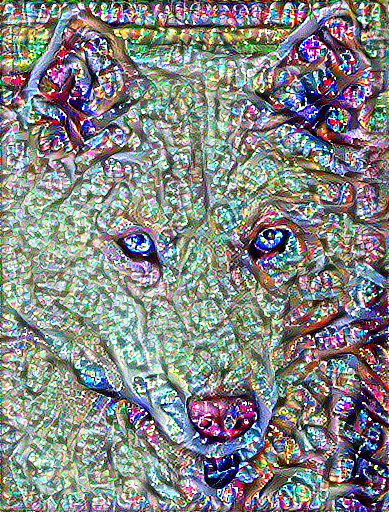

Epoch 20/80


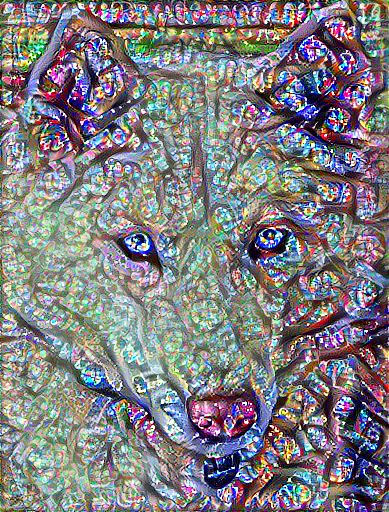

Epoch 30/80


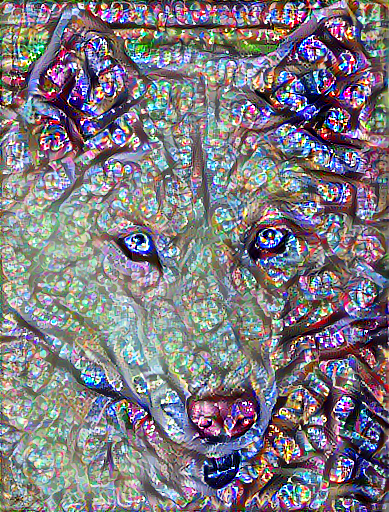

Epoch 40/80


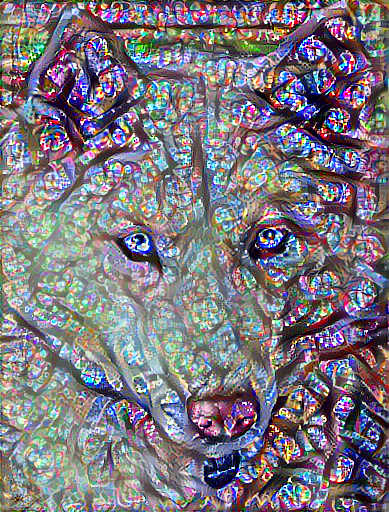

Epoch 50/80


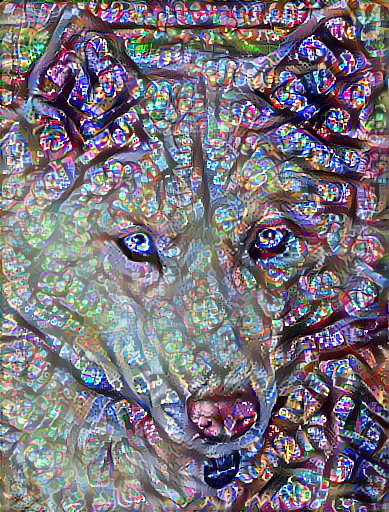

Epoch 60/80


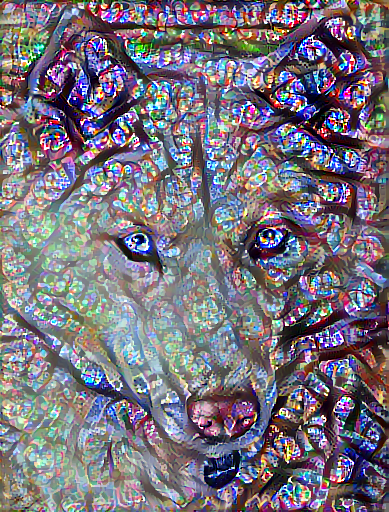

Epoch 70/80


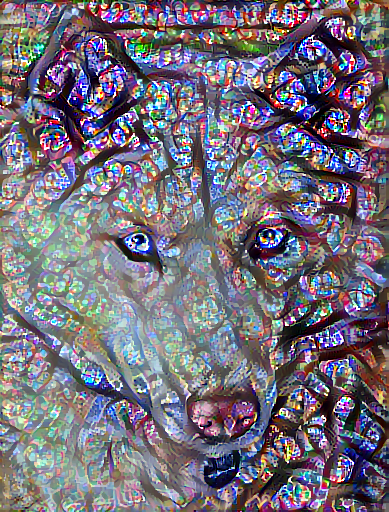

Epoch 80/80


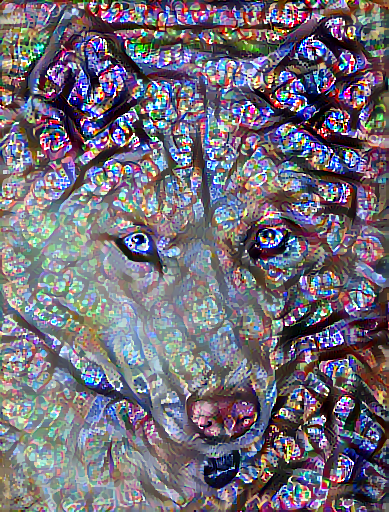

Total training time: 205.2 seconds


In [27]:
# Run optimization only when training a new image
if workflow.value == "train":
    start = time.time()

    epochs = 80
    steps_per_epoch = 32

    step = 0

    for n in range(epochs):
        for m in range(steps_per_epoch):
            step += 1
            train_step(image)

        # Display progress every 10 epochs
        if (n + 1) % 10 == 0:
            print(f"Epoch {n + 1}/{epochs}")
            display(tensor_to_image(image))

    end = time.time()
    print(f"Total training time: {end - start:.1f} seconds")

else:
    print("Training skipped. Saved image will be restored.")

# Checkpoints: save and restore

In [28]:
if workflow.value == "train":
    checkpoint_dir = Path("/content/drive/MyDrive/StyleTransfer_Checkpoints")
    checkpoint_dir.mkdir(parents=True, exist_ok=True)

    # Get original image names
    content_name = Path(content_path).stem.removeprefix("content_")
    style_name = Path(style_path).stem.removeprefix("style_")

    # Create filename
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

    checkpoint_path = checkpoint_dir / (
        f"{content_name}_{style_name}_{timestamp}.npy"
    )

    np.save(checkpoint_path, image.numpy())

    print(f"Trained image saved successfully: {checkpoint_path.name}")

else:
    print("Checkpoint saving skipped.")

Trained image saved successfully: winterserious_notredame (1)_20261110_165235.npy


In [29]:
if workflow.value == "restore":
    if checkpoint_selector.value is None:
        raise FileNotFoundError("No saved checkpoint selected.")

    checkpoint_path = Path(checkpoint_selector.value)

    restored_image = np.load(checkpoint_path)
    image = tf.Variable(restored_image, dtype=tf.float32)

    print(f"Restored checkpoint: {checkpoint_path.name}")
    display(tensor_to_image(image))

else:
    print("Restoration skipped. Using newly trained image.")

Restoration skipped. Using newly trained image.


Saved: stylized_style_colors.png


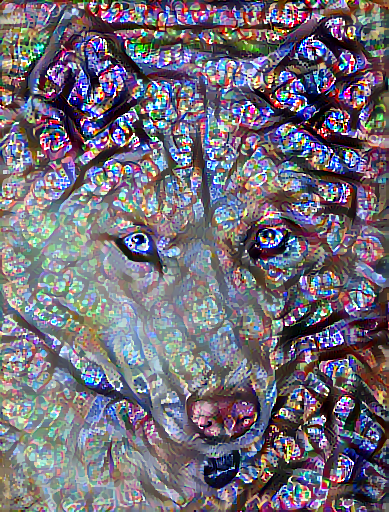

In [30]:
# Save the final image using the selected color mode
# change the color mode dropdown and rerun this cell to save the other
# version without retraining

if color_mode.value == "style":
    final_image = tensor_to_image(image)
    filename = "stylized_style_colors.png"

else:
    final_image = preserve_content_colors(image, content_image)
    filename = "stylized_original_colors.png"

final_image.save(filename)

print(f"Saved: {filename}")
display(final_image)

# Final output
Save whichever color version you selected in the StyleTransfer_Results folder (works whether you trained a new image or restored a checkpoint)

In [31]:
# Create the results folder if necessary
output_dir = Path("/content/drive/MyDrive/StyleTransfer_Results")
output_dir.mkdir(parents=True, exist_ok=True)

# Save the selected image with a unique filename
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
output_path = output_dir / f"{Path(filename).stem}_{timestamp}.png"

shutil.copy2(filename, output_path)

print(f"Image saved to Google Drive: {output_path}")

Image saved to Google Drive: /content/drive/MyDrive/StyleTransfer_Results/stylized_style_colors_20261110_165235.png
